# Smart Clustering System - SmartCart Customer Segmentation
**Machine Learning Mini-Project**

---

**Objective:** Group SmartCart's 2,240 customers by their shopping behaviour, then turn each group into a clear marketing plan.

**Project flow:**
1. Clean the data and create useful customer fields
2. Explore the main patterns
3. Compare K-Means, Ward clustering, and a Gaussian mixture model
4. Explain the four customer groups and suggest campaign tests
5. Use PCA as a final check for repeated information


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from IPython.display import display, Markdown

sns.set_style('whitegrid')
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10
})

COLORS = ['#E63946', '#457B9D', '#2A9D8F', '#E9C46A']


## 1. Data Preparation


### 1.1 Load the Dataset


In [2]:
df = pd.read_csv('smartcart_customers.csv')
print(f"Shape: {df.shape[0]} customers x {df.shape[1]} features")
df.head()


Shape: 2240 customers x 22 features


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


### 1.2 Missing Values
Only `Income` has missing values (24 entries). We fill them with the median. The median is less affected by the very large income value than the mean.


In [3]:
print("Missing before:", df.isnull().sum().sum())
df['Income'] = df['Income'].fillna(df['Income'].median())
print("Missing after :", df.isnull().sum().sum())


Missing before: 24
Missing after : 0


### 1.3 Feature Engineering
Raw columns like six separate product amounts and multiple family columns are hard to cluster on directly.
We aggregate them into interpretable features:


In [4]:
df['Age'] = 2026 - df['Year_Birth']
df['Total_Children'] = df['Kidhome'] + df['Teenhome']

df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst=True)
df['Customer_Tenure_Days'] = (df['Dt_Customer'].max() - df['Dt_Customer']).dt.days

SPEND_COLS = ['MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Spending']  = df[SPEND_COLS].sum(axis=1)
df['Total_Purchases'] = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)

df['Education'] = df['Education'].replace({
    'Basic': 'Undergrad', '2n Cycle': 'Undergrad',
    'Graduation': 'Graduate', 'Master': 'Postgrad', 'PhD': 'Postgrad'
})
df['Living_With'] = df['Marital_Status'].replace({
    'Married': 'Partner', 'Together': 'Partner',
    'Single': 'Alone', 'Divorced': 'Alone',
    'Widow': 'Alone', 'Absurd': 'Alone', 'YOLO': 'Alone'
})

df[['Age', 'Total_Children', 'Total_Spending', 'Total_Purchases', 'Education', 'Living_With']].head()


,Age,Total_Children,Total_Spending,Total_Purchases,Education,Living_With
0,69,0,1617,22,Graduate,Alone
1,72,2,27,4,Graduate,Alone
2,61,0,776,20,Graduate,Partner
3,42,1,53,6,Graduate,Partner
4,45,1,422,14,Postgrad,Partner


### 1.4 Drop Redundant Columns
The original columns that were aggregated above are no longer needed.


In [5]:
to_drop = ['ID', 'Year_Birth', 'Marital_Status', 'Kidhome',
           'Teenhome', 'Dt_Customer'] + SPEND_COLS
df_clean = df.drop(columns=to_drop)
print(f"After dropping: {df_clean.shape[0]} rows × {df_clean.shape[1]} columns")


After dropping: 2240 rows × 16 columns


### 1.5 Outlier Removal
The scatter below reveals two clear data-entry anomalies:
- One customer with **Age > 120** (impossible birth year)
- One customer with **Income > ₹600,000** (extreme outlier)

Both would drag cluster centres away from the real patterns, so we remove them.


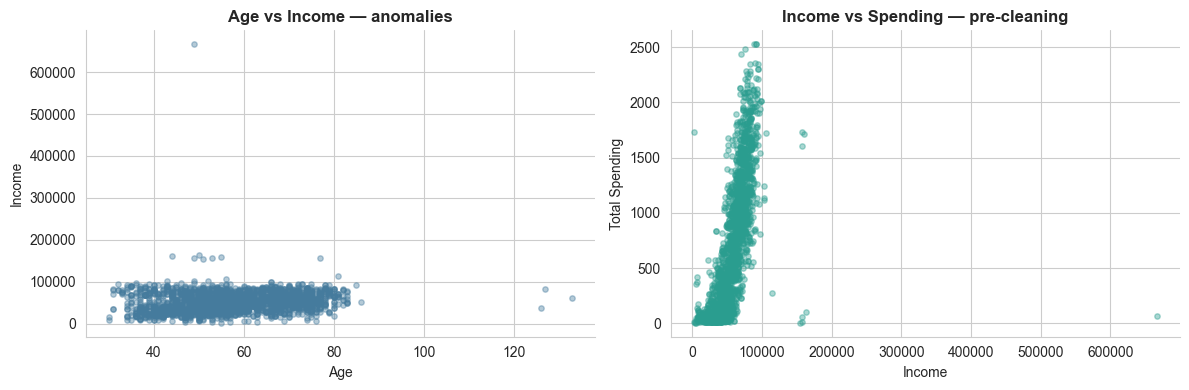

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df_clean['Age'], df_clean['Income'], alpha=0.4, s=15, c='#457B9D')
axes[0].set_xlabel('Age'); axes[0].set_ylabel('Income')
axes[0].set_title('Age vs Income — anomalies', fontweight='bold')

axes[1].scatter(df_clean['Income'], df_clean['Total_Spending'], alpha=0.4, s=15, c='#2A9D8F')
axes[1].set_xlabel('Income'); axes[1].set_ylabel('Total Spending')
axes[1].set_title('Income vs Spending — pre-cleaning', fontweight='bold')

plt.tight_layout()
plt.show()


In [7]:
before = len(df_clean)
df_clean = df_clean[(df_clean['Age'] < 90) & (df_clean['Income'] < 600_000)].copy()
print(f"Removed {before - len(df_clean)} anomalies → {len(df_clean)} customers remain")


Removed 4 anomalies → 2236 customers remain


## 2. Exploratory Data Analysis


### 2.1 Feature Distributions


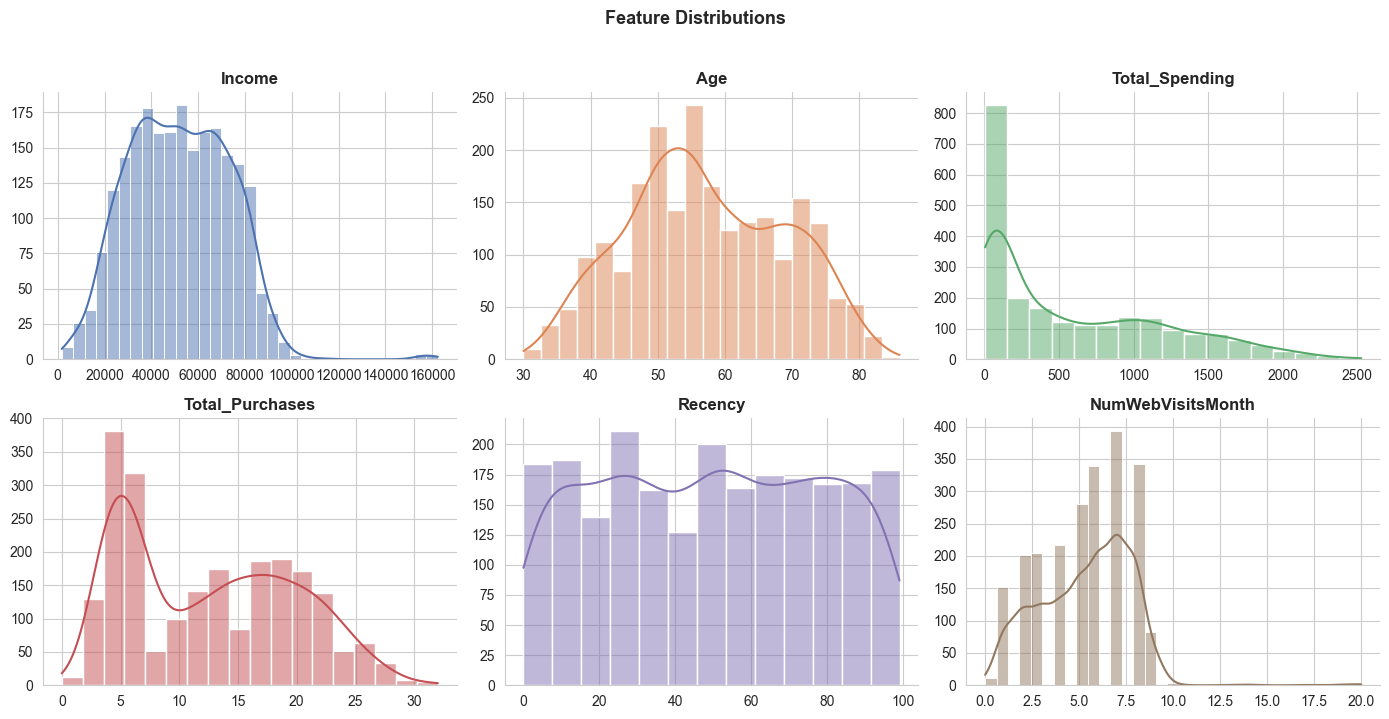

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
dist_feats  = ['Income', 'Age', 'Total_Spending', 'Total_Purchases', 'Recency', 'NumWebVisitsMonth']
dist_colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860']

for ax, col, clr in zip(axes.flatten(), dist_feats, dist_colors):
    sns.histplot(df_clean[col], kde=True, color=clr, edgecolor='white', ax=ax)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel(''); ax.set_ylabel('')

plt.suptitle('Feature Distributions', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 2.2 Correlation Heatmap


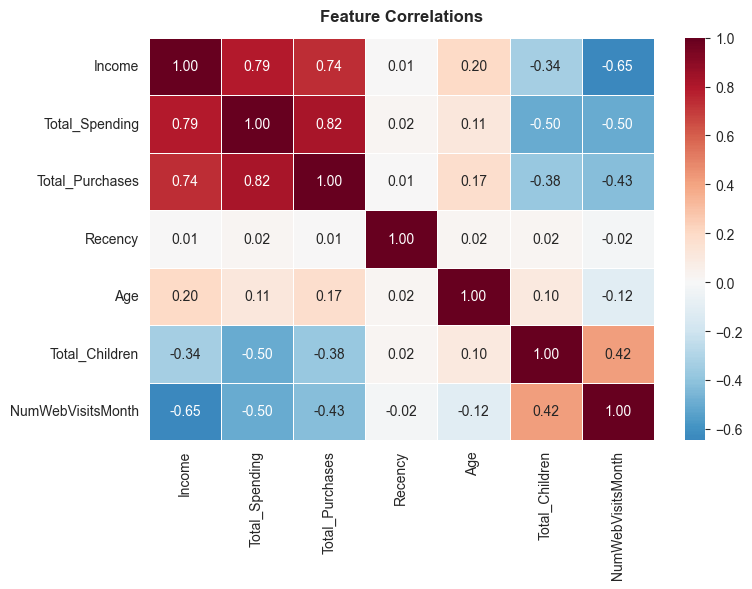

In [9]:
corr_cols = ['Income', 'Total_Spending', 'Total_Purchases', 'Recency',
             'Age', 'Total_Children', 'NumWebVisitsMonth']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5, annot_kws={'size': 10}, ax=ax)
ax.set_title('Feature Correlations', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 3. Model Setup

**Inputs:** The model uses seven customer fields: Income, Total Spending, Total Purchases, Recency, Age, Total Children, and monthly web visits.

`Response` and `Complain` are left out because they are results to check later, not information that should create the groups.

**Putting fields on one scale:** The seven fields use different units. StandardScaler changes them to a common scale so that a large number, such as Income, does not control the grouping only because of its unit.


In [10]:
le = LabelEncoder()
df_enc = df_clean.copy()
df_enc['Education']   = le.fit_transform(df_clean['Education'])
df_enc['Living_With'] = le.fit_transform(df_clean['Living_With'])

FEATURES = ['Income', 'Total_Spending', 'Total_Purchases', 'Recency',
            'Age', 'Total_Children', 'NumWebVisitsMonth']

X = df_enc[FEATURES]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Clustering on {len(FEATURES)} features, {X_scaled.shape[0]} samples")
print("Scaled check — mean ≈ 0, std ≈ 1:")
display(pd.DataFrame(X_scaled, columns=FEATURES).agg(['mean','std']).round(3))


Clustering on 7 features, 2236 samples
Scaled check — mean ≈ 0, std ≈ 1:


,Income,Total_Spending,Total_Purchases,Recency,Age,Total_Children,NumWebVisitsMonth
mean,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 4. Choosing K (Number of Clusters)

Two complementary methods:
- **Elbow (WCSS):** Plot of within-cluster sum of squares. The "elbow" shows where adding more clusters stops helping much.
- **Silhouette Score:** Measures how well each point fits its own cluster vs neighbouring clusters. Higher = better separated. Range: −1 to +1.


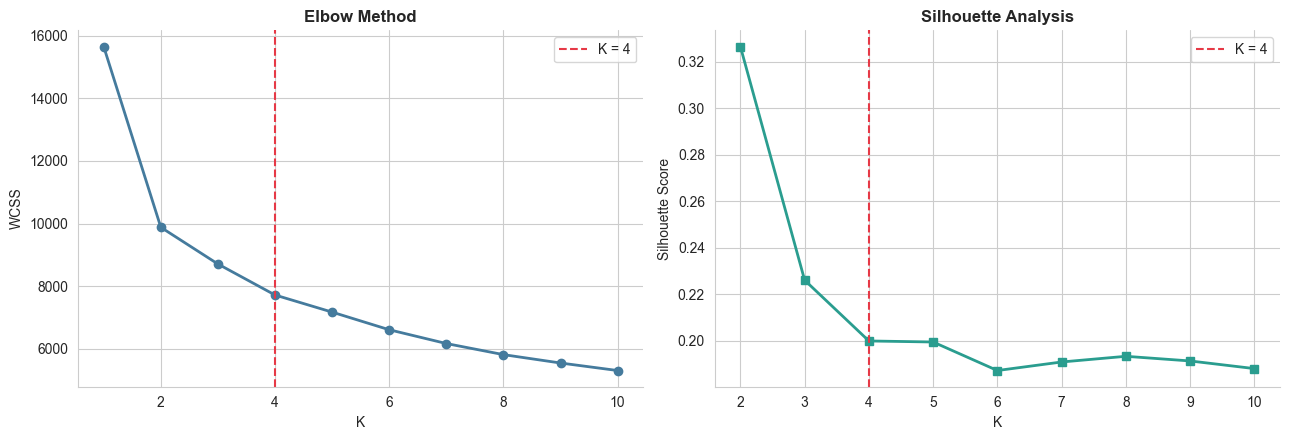

K=2 has the highest silhouette score. K=4 is retained because the elbow supports it and four groups provide more useful customer profiles.


In [11]:
K_range = range(2, 11)
wcss, sil_scores = [], []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labs = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labs))

# Also need K=1 for elbow
wcss_full = [KMeans(n_clusters=1, random_state=42, n_init=10).fit(X_scaled).inertia_] + wcss

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(range(1, 11), wcss_full, 'o-', color='#457B9D', lw=2, markersize=6)
ax1.axvline(4, color='#E63946', ls='--', lw=1.5, label='K = 4')
ax1.set_xlabel('K'); ax1.set_ylabel('WCSS')
ax1.set_title('Elbow Method', fontweight='bold')
ax1.legend()

ax2.plot(K_range, sil_scores, 's-', color='#2A9D8F', lw=2, markersize=6)
ax2.axvline(4, color='#E63946', ls='--', lw=1.5, label='K = 4')
ax2.set_xlabel('K'); ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()

best_k = list(K_range)[int(np.argmax(sil_scores))]
print(f"K={best_k} has the highest silhouette score. K=4 is retained because the elbow supports it and four groups provide more useful customer profiles.")


## 5. Clustering — Three Algorithms Compared

| Algorithm | Type | How it works |
|---|---|---|
| **K-Means** | Centroid | Assigns each point to the nearest of K centres; iterates until stable |
| **Agglomerative** | Hierarchical | Starts with each point as its own cluster, merges closest pairs bottom-up |
| **GMM** | Probabilistic | Models each cluster as a Gaussian distribution; assigns soft probabilities |


### 5.1 Agglomerative Clustering — Dendrogram


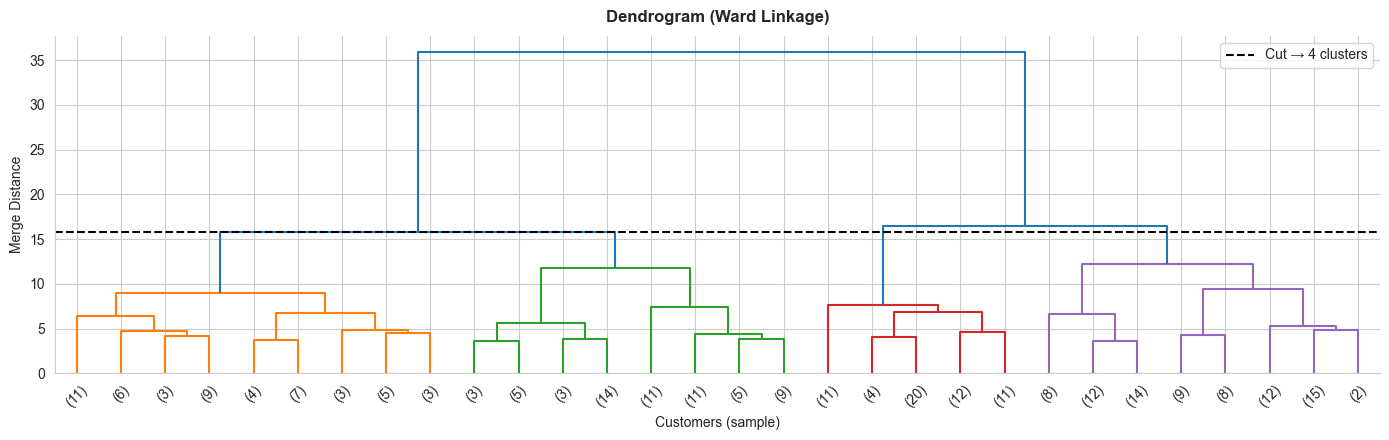

In [12]:
K = 4

# Dendrogram on a random sample of 250 customers
idx = np.random.RandomState(42).choice(len(X_scaled), 250, replace=False)
Z = linkage(X_scaled[idx], method='ward')

fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True,
           leaf_rotation=45, color_threshold=Z[-3, 2], ax=ax)
ax.axhline(Z[-3, 2], color='black', ls='--', lw=1.5, label='Cut → 4 clusters')
ax.set_title('Dendrogram (Ward Linkage)', fontweight='bold', pad=10)
ax.set_xlabel('Customers (sample)'); ax.set_ylabel('Merge Distance')
ax.legend()
plt.tight_layout()
plt.show()


### 5.2 Run All Three Algorithms


In [13]:
# K-Means
km = KMeans(n_clusters=K, random_state=42, n_init=10)
labels_km  = km.fit_predict(X_scaled)
sil_km     = silhouette_score(X_scaled, labels_km)

# Agglomerative (Ward)
agg = AgglomerativeClustering(n_clusters=K, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)
sil_agg    = silhouette_score(X_scaled, labels_agg)

# GMM
gmm = GaussianMixture(n_components=K, random_state=42, n_init=5)
labels_gmm = gmm.fit_predict(X_scaled)
sil_gmm    = silhouette_score(X_scaled, labels_gmm)

# Comparison table
results = pd.DataFrame({
    'Algorithm'      : ['K-Means', 'Agglomerative (Ward)', 'GMM'],
    'Silhouette'     : [sil_km, sil_agg, sil_gmm],
    'Cluster 0'      : [int((labels_km==0).sum()), int((labels_agg==0).sum()), int((labels_gmm==0).sum())],
    'Cluster 1'      : [int((labels_km==1).sum()), int((labels_agg==1).sum()), int((labels_gmm==1).sum())],
    'Cluster 2'      : [int((labels_km==2).sum()), int((labels_agg==2).sum()), int((labels_gmm==2).sum())],
    'Cluster 3'      : [int((labels_km==3).sum()), int((labels_agg==3).sum()), int((labels_gmm==3).sum())],
}).sort_values('Silhouette', ascending=False).reset_index(drop=True)

display(results.style.format({'Silhouette': '{:.4f}'})
        .background_gradient(cmap='Blues', subset=['Silhouette']))

print(f"\nBest: K-Means (Silhouette = {sil_km:.4f})")


,Algorithm,Silhouette,Cluster 0,Cluster 1,Cluster 2,Cluster 3
0,K-Means,0.2000,656,598,492,490
1,Agglomerative (Ward),0.1391,862,492,533,349
2,GMM,0.0802,359,635,255,987



Best: K-Means (Silhouette = 0.2000)


### 5.3 Visual Comparison — How Each Algorithm Draws Boundaries


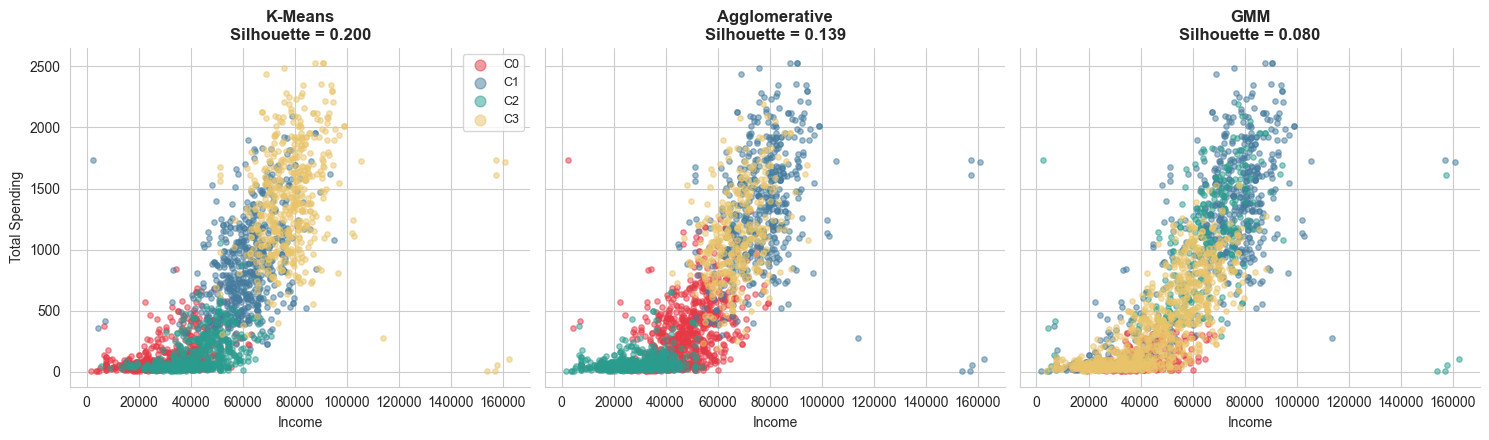

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
algos = [('K-Means', labels_km, sil_km),
         ('Agglomerative', labels_agg, sil_agg),
         ('GMM', labels_gmm, sil_gmm)]

for ax, (name, labs, sil_val) in zip(axes, algos):
    for c in range(K):
        m = labs == c
        ax.scatter(df_clean['Income'].values[m], df_clean['Total_Spending'].values[m],
                   c=COLORS[c], alpha=0.5, s=15, label=f'C{c}')
    ax.set_title(f'{name}\nSilhouette = {sil_val:.3f}', fontweight='bold')
    ax.set_xlabel('Income')

axes[0].set_ylabel('Total Spending')
axes[0].legend(markerscale=2, fontsize=9)
plt.tight_layout()
plt.show()


In [15]:
# Assign final labels from the best algorithm
final_labels = labels_km
df_prof = df_clean.copy().reset_index(drop=True)
df_prof['Cluster'] = final_labels


## 6. Cluster Profiling
Now we examine what makes each segment different.


### 6.1 Summary Table


In [16]:
summary = df_prof.groupby('Cluster')[FEATURES].mean().round(1)
summary.insert(0, 'Count', df_prof['Cluster'].value_counts().sort_index())
display(summary.style.background_gradient(cmap='Greens', subset=['Income', 'Total_Spending']))


,Count,Income,Total_Spending,Total_Purchases,Recency,Age,Total_Children,NumWebVisitsMonth
Cluster,,,,,,,,
0,656,30803.500000,122.000000,6.300000,48.000000,49.000000,0.800000,6.900000
1,598,61516.600000,863.800000,18.500000,48.900000,62.000000,1.000000,5.300000
2,492,42173.600000,147.500000,7.100000,50.200000,62.200000,1.900000,6.200000
3,490,78413.500000,1399.500000,19.100000,49.700000,56.900000,0.100000,2.300000


### 6.2 Box Plots — Feature Spread per Cluster
Each box shows the spread within a cluster. The line in the middle is the median.
Points beyond the whiskers are *not* errors — they represent naturally extreme customers within that segment (e.g., a big spender within the moderate group).


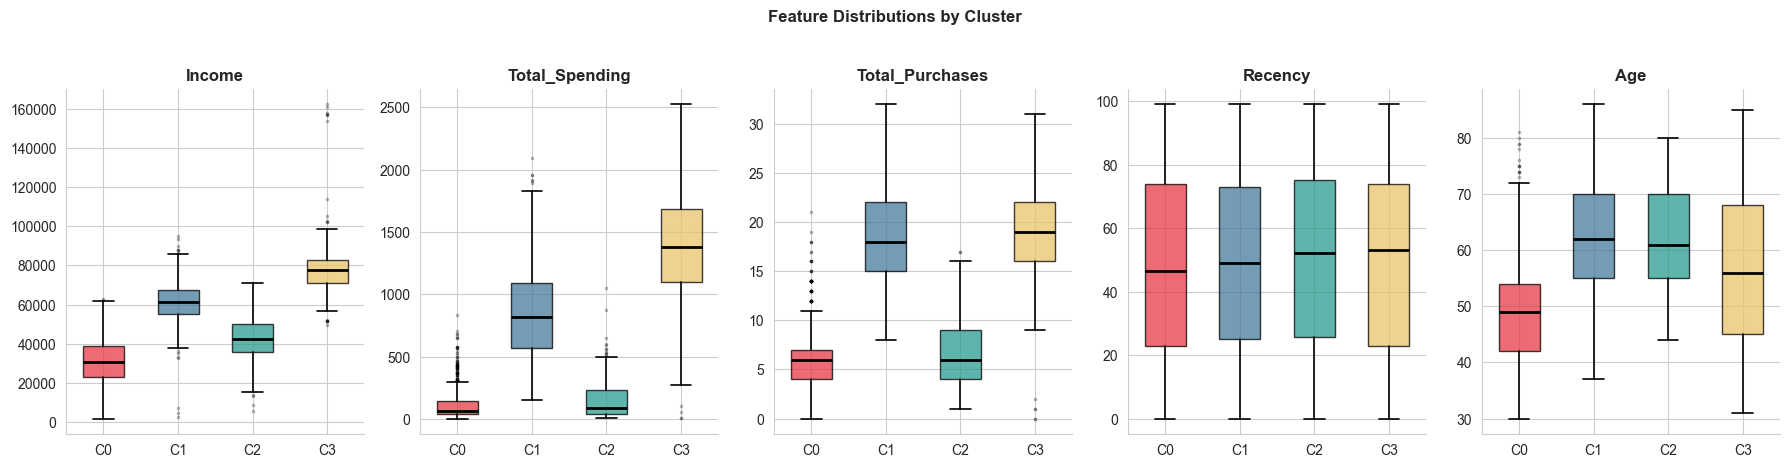

In [17]:
box_feats = ['Income', 'Total_Spending', 'Total_Purchases', 'Recency', 'Age']

fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, feat in zip(axes, box_feats):
    bp = ax.boxplot(
        [df_prof.loc[df_prof['Cluster'] == c, feat] for c in range(K)],
        patch_artist=True, widths=0.55,
        medianprops=dict(color='black', linewidth=2),
        flierprops=dict(marker='.', markersize=3, alpha=0.3),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2))
    for patch, clr in zip(bp['boxes'], COLORS):
        patch.set_facecolor(clr)
        patch.set_alpha(0.75)
    ax.set_xticklabels([f'C{c}' for c in range(K)])
    ax.set_title(feat, fontweight='bold')
    if ax != axes[0]: ax.set_ylabel('')

plt.suptitle('Feature Distributions by Cluster', fontweight='bold', fontsize=12, y=1.03)
plt.tight_layout()
plt.show()


### 6.3 Radar Chart — Cluster Fingerprints


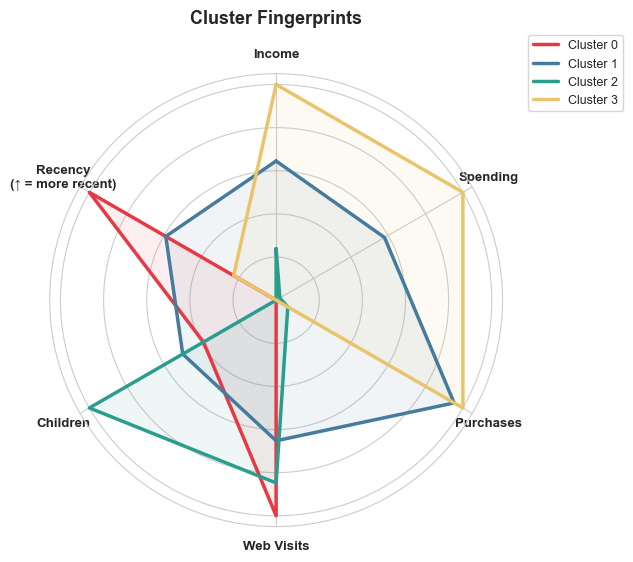

In [18]:
radar_feats  = ['Income', 'Total_Spending', 'Total_Purchases',
                'NumWebVisitsMonth', 'Total_Children', 'Recency']
radar_labels = ['Income', 'Spending', 'Purchases',
                'Web Visits', 'Children', 'Recency\n(↑ = more recent)']

# Normalise each feature to 0–1 across clusters
norm = summary[radar_feats].copy()
for col in radar_feats:
    lo, hi = norm[col].min(), norm[col].max()
    norm[col] = (norm[col] - lo) / (hi - lo + 1e-9)
norm['Recency'] = 1 - norm['Recency']   # invert: lower recency number = more recent = better

N = len(radar_feats)
angles = [n / N * 2 * np.pi for n in range(N)] + [0]

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels, fontsize=9.5, fontweight='bold')
ax.set_yticklabels([])

for c in range(K):
    vals = norm.loc[c, radar_feats].tolist() + [norm.loc[c, radar_feats[0]]]
    ax.plot(angles, vals, color=COLORS[c], linewidth=2.5, label=f'Cluster {c}')
    ax.fill(angles, vals, color=COLORS[c], alpha=0.08)

ax.set_title('Cluster Fingerprints', fontweight='bold', size=13, pad=18)
ax.legend(loc='upper right', bbox_to_anchor=(1.28, 1.1), fontsize=9)
plt.tight_layout()
plt.show()


### 6.4 Income vs Spending — Final Segments


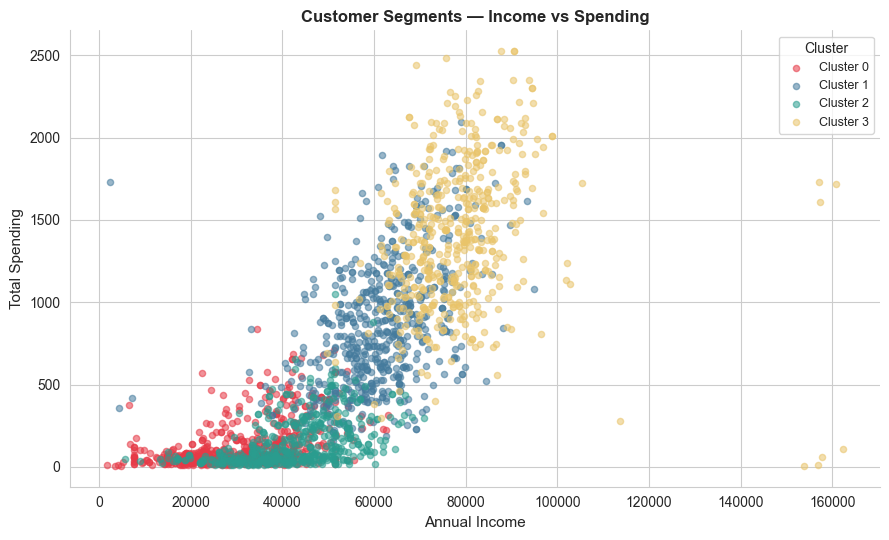

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for c in range(K):
    m = df_prof['Cluster'] == c
    ax.scatter(df_prof.loc[m, 'Income'], df_prof.loc[m, 'Total_Spending'],
               c=COLORS[c], s=20, alpha=0.55, label=f'Cluster {c}')

ax.set_xlabel('Annual Income', fontsize=11)
ax.set_ylabel('Total Spending', fontsize=11)
ax.set_title('Customer Segments — Income vs Spending', fontweight='bold', fontsize=12)
ax.legend(title='Cluster', fontsize=9)
plt.tight_layout()
plt.show()


## 7. External Validation
`Response` (whether a customer accepted the last marketing campaign) was **not** used in clustering.
If our clusters show different response rates, it means the segmentation is capturing genuinely different customer types — not just a statistical artefact.


### 7.1 Product Category Breakdown


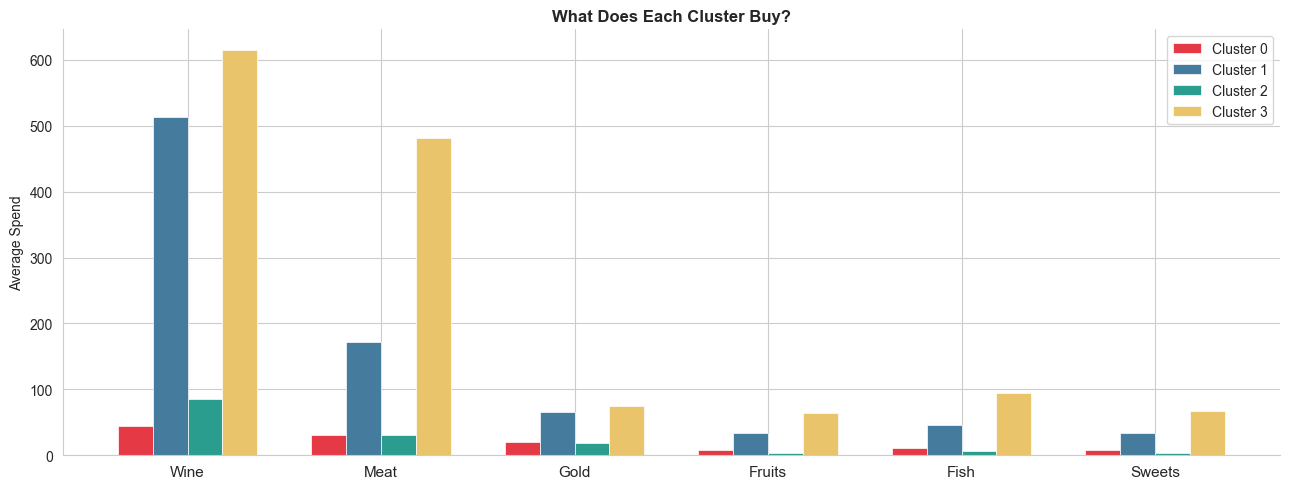

In [20]:
df_full = df[(df['Age'] < 90) & (df['Income'] < 600_000)].copy().reset_index(drop=True)
df_full['Cluster'] = final_labels

prod_cols   = ['MntWines', 'MntMeatProducts', 'MntGoldProds',
               'MntFruits', 'MntFishProducts', 'MntSweetProducts']
prod_labels = ['Wine', 'Meat', 'Gold', 'Fruits', 'Fish', 'Sweets']
prod_mean   = df_full.groupby('Cluster')[prod_cols].mean()

x = np.arange(len(prod_labels))
w = 0.18

fig, ax = plt.subplots(figsize=(13, 5))
for c in range(K):
    ax.bar(x + c*w, prod_mean.iloc[c], w, color=COLORS[c],
           label=f'Cluster {c}', edgecolor='white', linewidth=0.5)

ax.set_xticks(x + w*1.5)
ax.set_xticklabels(prod_labels, fontsize=11)
ax.set_ylabel('Average Spend')
ax.set_title('What Does Each Cluster Buy?', fontweight='bold', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()


### 7.2 Campaign Response Rate


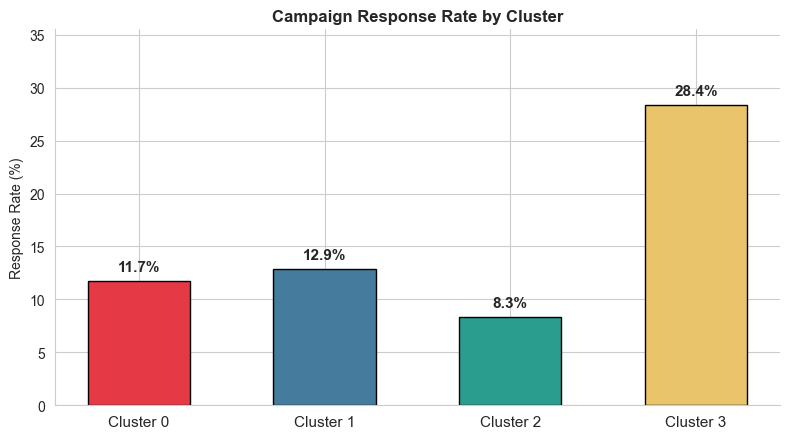

Cluster 3 (high spenders) responds at 28.4% — nearly 3× the average.
This confirms our clustering captured real behavioural differences.


In [21]:
resp = (df_full.groupby('Cluster')['Response'].mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(range(K), resp, color=COLORS, edgecolor='black',
              linewidth=1, width=0.55)
ax.bar_label(bars, fmt='%.1f%%', padding=5, fontweight='bold', fontsize=11)
ax.set_xticks(range(K))
ax.set_xticklabels([f'Cluster {c}' for c in range(K)], fontsize=11)
ax.set_ylabel('Response Rate (%)')
ax.set_title('Campaign Response Rate by Cluster', fontweight='bold', fontsize=12)
ax.set_ylim(0, resp.max() * 1.25)
plt.tight_layout()
plt.show()

print("Cluster 3 (high spenders) responds at 28.4% — nearly 3× the average.")
print("This confirms our clustering captured real behavioural differences.")


## 8. Customer Groups and Marketing Plans
Each group receives a simple name based on its strongest features. The suggested actions are campaign ideas to test, not guaranteed results.


In [22]:
# Name each group from its strongest features
spend_rank = summary['Total_Spending'].rank(ascending=False)
child_rank = summary['Total_Children'].rank(ascending=False)
web_rank   = summary['NumWebVisitsMonth'].rank(ascending=False)

personas = {}
for c in range(K):
    if spend_rank[c] == 1:
        personas[c] = 'The Elite'
    elif spend_rank[c] >= 3 and child_rank[c] <= 2:
        personas[c] = 'Value Families'
    elif spend_rank[c] >= 3 and web_rank[c] <= 2:
        personas[c] = 'Digital Browsers'
    else:
        personas[c] = 'Mainstream Regulars'

df_prof['Persona'] = df_prof['Cluster'].map(personas)

strategies = {
    'The Elite': {
        'profile': 'Highest income, spending, and purchases. They buy the most wine and meat and visit the website less often.',
        'tactics': [
            'Offer early access to premium products.',
            'Use loyalty rewards that protect retention.',
            'Recommend products from their past purchases.'
        ]
    },
    'Mainstream Regulars': {
        'profile': 'Steady income, spending, and purchases across several product types.',
        'tactics': [
            'Test a spend-and-save bundle.',
            'Suggest a related product at checkout.',
            'Use simple loyalty points for repeat purchases.'
        ]
    },
    'Value Families': {
        'profile': 'Largest households, lower spending, and frequent website visits.',
        'tactics': [
            'Test family bundles and larger packs.',
            'Run offers around school holidays.',
            'Show the saving per item clearly.'
        ]
    },
    'Digital Browsers': {
        'profile': 'Most website visits but the lowest spending and purchases.',
        'tactics': [
            'Test a short checkout reminder.',
            'Offer free delivery above a clear order value.',
            'Use a short, time-limited offer to encourage checkout.'
        ]
    }
}

print("CUSTOMER GROUPS AND MARKETING TESTS")
print()
for c in range(K):
    name = personas[c]
    count = int(summary.loc[c, 'Count'])
    pct   = count / len(df_prof) * 100
    info  = strategies[name]

    print(f"Cluster {c}: {name} ({count} customers, {pct:.0f}%)")
    print(f"What the data show: {info['profile']}")
    print("Ideas to test:")
    for t in info['tactics']:
        print(f"  - {t}")
    print()


CUSTOMER GROUPS AND MARKETING TESTS

Cluster 0: Digital Browsers (656 customers, 29%)
What the data show: Most website visits but the lowest spending and purchases.
Ideas to test:
  - Test a short checkout reminder.
  - Offer free delivery above a clear order value.
  - Use a short, time-limited offer to encourage checkout.

Cluster 1: Mainstream Regulars (598 customers, 27%)
What the data show: Steady income, spending, and purchases across several product types.
Ideas to test:
  - Test a spend-and-save bundle.
  - Suggest a related product at checkout.
  - Use simple loyalty points for repeat purchases.

Cluster 2: Value Families (492 customers, 22%)
What the data show: Largest households, lower spending, and frequent website visits.
Ideas to test:
  - Test family bundles and larger packs.
  - Run offers around school holidays.
  - Show the saving per item clearly.

Cluster 3: The Elite (490 customers, 22%)
What the data show: Highest income, spending, and purchases. They buy the most

## 10. Conclusion


In [23]:
print("FINAL RESULT")
print()
print(f"Starting data: {len(df)} customers and 22 fields")
print(f"After cleaning: {len(df_prof)} customers and 7 model fields")
print("Methods compared: K-Means, Ward clustering, and Gaussian mixture model")
print(f"Selected method: K-Means (separation score = {sil_km:.4f})")
print("Selected groups: 4 (two groups separated best, but four gave more useful customer types)")
print()
print()

print("CUSTOMER GROUPS")
print()
final_table = []
for c in range(K):
    final_table.append({
        'Cluster': c,
        'Customer group': personas[c],
        'Customers': int(summary.loc[c, 'Count']),
        'Average income': f"{summary.loc[c, 'Income']:,.0f}",
        'Average spending': f"{summary.loc[c, 'Total_Spending']:,.0f}"
    })

results_df = pd.DataFrame(final_table).set_index('Cluster')
display(results_df)


FINAL RESULT

Starting data: 2240 customers and 22 fields
After cleaning: 2236 customers and 7 model fields
Methods compared: K-Means, Ward clustering, and Gaussian mixture model
Selected method: K-Means (separation score = 0.2000)
Selected groups: 4 (two groups separated best, but four gave more useful customer types)


CUSTOMER GROUPS



,Customer group,Customers,Average income,Average spending
Cluster,,,,
0,Digital Browsers,656,"30,804",122
1,Mainstream Regulars,598,"61,517",864
2,Value Families,492,"42,174",148
3,The Elite,490,"78,414","1,400"
